# PCPP

In [1]:

import numpy as np


def sample_pcpp_exact(n, theta, omega, random_state=None):
    """
    Generate a sample from the exact PCPP generative process.

    Parameters
    ----------
    n : int
        Number of observations.
    theta : float
        Poisson parameter for the number of potential communities.
    omega : float
        Competition parameter in [0, 1].
    random_state : int or None
        Random seed.

    Returns
    -------
    dict
        Generated number of communities, tournament outcomes, allocation
        weights, assignments, and induced partition.
    """
    if n < 1:
        raise ValueError("n must be positive.")
    if theta <= 0:
        raise ValueError("theta must be positive.")
    if not 0 <= omega <= 1:
        raise ValueError("omega must belong to [0, 1].")

    rng = np.random.default_rng(random_state)

    # 1. Number of potential communities
    M = 1 + rng.poisson(theta)

    # 2. Random tournament
    D = np.zeros(M, dtype=int)
    tournament = []

    for j in range(M):
        for l in range(j + 1, M):
            win = rng.binomial(1, 0.5)

            if win == 1:
                D[j] += 1
                winner, loser = j, l
            else:
                D[l] += 1
                winner, loser = l, j

            tournament.append((winner, loser))

    # 3. Allocation weights
    W = (
        (1 - omega) / M
        + omega * (1 + 2 * D) / M**2
    )

    # Numerical normalization
    W = W / W.sum()

    # 4. Allocation of observations
    xi = rng.choice(M, size=n, p=W)

    # 5. Induced partition
    labels, inverse, counts = np.unique(
        xi,
        return_inverse=True,
        return_counts=True
    )

    blocks = [
        np.where(inverse == k)[0].tolist()
        for k in range(len(labels))
    ]

    return {
        "process": "Exact PCPP",
        "M": M,
        "D": D,
        "W": W,
        "tournament": tournament,
        "xi_raw": xi,
        "canonical_xi": inverse,
        "K_n": len(labels),
        "block_sizes": counts.tolist(),
        "blocks": blocks
    }


def sample_pcpp_approximate(n, theta, omega, random_state=None):
    """
    Generate a sample from the Dirichlet-approximated PCPP.

    Conditional on M, the allocation weights follow a symmetric
    Dirichlet distribution with parameter

        alpha_M = M / omega**2 - 1 / M.

    For omega = 0, the allocation weights are uniform.
    """
    if n < 1:
        raise ValueError("n must be positive.")
    if theta <= 0:
        raise ValueError("theta must be positive.")
    if not 0 <= omega <= 1:
        raise ValueError("omega must belong to [0, 1].")

    rng = np.random.default_rng(random_state)

    # 1. Number of potential communities
    M = 1 + rng.poisson(theta)

    # 2. Approximate allocation weights
    if omega == 0 or M == 1:
        W = np.full(M, 1.0 / M)
        alpha_M = None
    else:
        alpha_M = M / omega**2 - 1 / M

        if alpha_M <= 0:
            raise ValueError("The Dirichlet parameter must be positive.")

        W = rng.dirichlet(np.full(M, alpha_M))

    # 3. Allocation of observations
    xi = rng.choice(M, size=n, p=W)

    # 4. Induced partition
    labels, inverse, counts = np.unique(
        xi,
        return_inverse=True,
        return_counts=True
    )

    blocks = [
        np.where(inverse == k)[0].tolist()
        for k in range(len(labels))
    ]

    return {
        "process": "Approximate PCPP",
        "M": M,
        "alpha_M": alpha_M,
        "D": None,
        "W": W,
        "tournament": None,
        "xi_raw": xi,
        "canonical_xi": inverse,
        "K_n": len(labels),
        "block_sizes": counts.tolist(),
        "blocks": blocks
    }


            process  mean_K_n    sd_K_n  mean_largest_block  \
0  Approximate PCPP   4.00632  1.734480           384.18022   
1        Exact PCPP   3.98784  1.723958           388.19280   

   mean_largest_block_proportion  
0                       0.384180  
1                       0.388193  


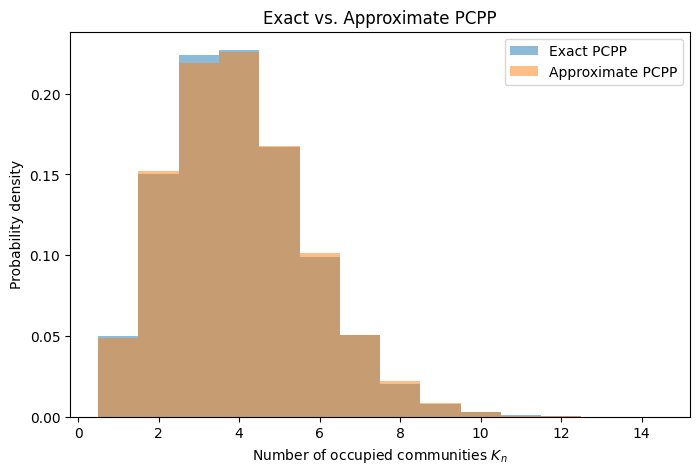

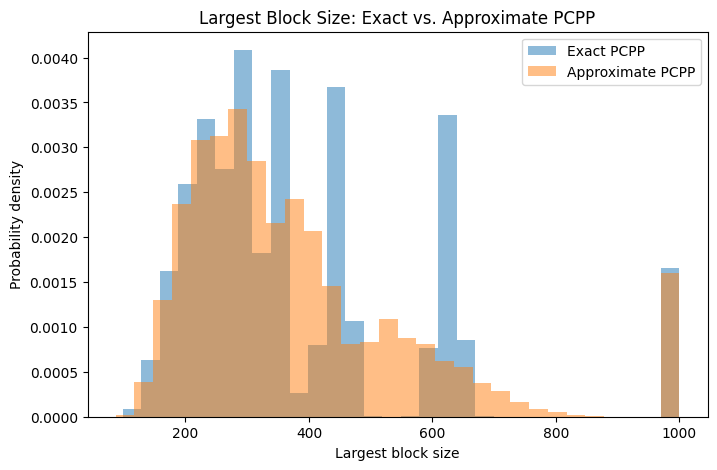

In [6]:

import pandas as pd


def compare_pcpp_processes(
    n,
    theta,
    omega,
    n_simulations=5000,
    random_state=123
):
    """
    Compare the exact and approximate PCPP through Monte Carlo simulation.
    """
    rng = np.random.default_rng(random_state)

    results = []

    for simulation in range(n_simulations):
        seed_exact = int(rng.integers(0, 2**32 - 1))
        seed_approx = int(rng.integers(0, 2**32 - 1))

        exact_sample = sample_pcpp_exact(
            n=n,
            theta=theta,
            omega=omega,
            random_state=seed_exact
        )

        approximate_sample = sample_pcpp_approximate(
            n=n,
            theta=theta,
            omega=omega,
            random_state=seed_approx
        )

        for sample in [exact_sample, approximate_sample]:
            largest_block = max(sample["block_sizes"])

            results.append({
                "simulation": simulation,
                "process": sample["process"],
                "K_n": sample["K_n"],
                "largest_block": largest_block,
                "largest_block_proportion": largest_block / n
            })

    results_df = pd.DataFrame(results)

    summary = (
        results_df
        .groupby("process")
        .agg(
            mean_K_n=("K_n", "mean"),
            sd_K_n=("K_n", "std"),
            mean_largest_block=("largest_block", "mean"),
            mean_largest_block_proportion=(
                "largest_block_proportion", "mean"
            )
        )
        .reset_index()
    )

    return results_df, summary


# Example
n = 1000
theta = 3.0
omega = 0.5

results_df, summary = compare_pcpp_processes(
    n=n,
    theta=theta,
    omega=omega,
    n_simulations=50000,
    random_state=123
)

print(summary)




import matplotlib.pyplot as plt


# Distribution of the number of occupied communities
plt.figure(figsize=(8, 5))

for process in results_df["process"].unique():
    subset = results_df[results_df["process"] == process]

    plt.hist(
        subset["K_n"],
        bins=np.arange(0.5, subset["K_n"].max() + 1.5),
        density=True,
        alpha=0.5,
        label=process
    )

plt.xlabel("Number of occupied communities $K_n$")
plt.ylabel("Probability density")
plt.title("Exact vs. Approximate PCPP")
plt.legend()
plt.show()


# Distribution of the largest block size
plt.figure(figsize=(8, 5))

for process in results_df["process"].unique():
    subset = results_df[results_df["process"] == process]

    plt.hist(
        subset["largest_block"],
        bins=30,
        density=True,
        alpha=0.5,
        label=process
    )

plt.xlabel("Largest block size")
plt.ylabel("Probability density")
plt.title("Largest Block Size: Exact vs. Approximate PCPP")
plt.legend()
plt.show()


# Visualizar una realización de la PCPP

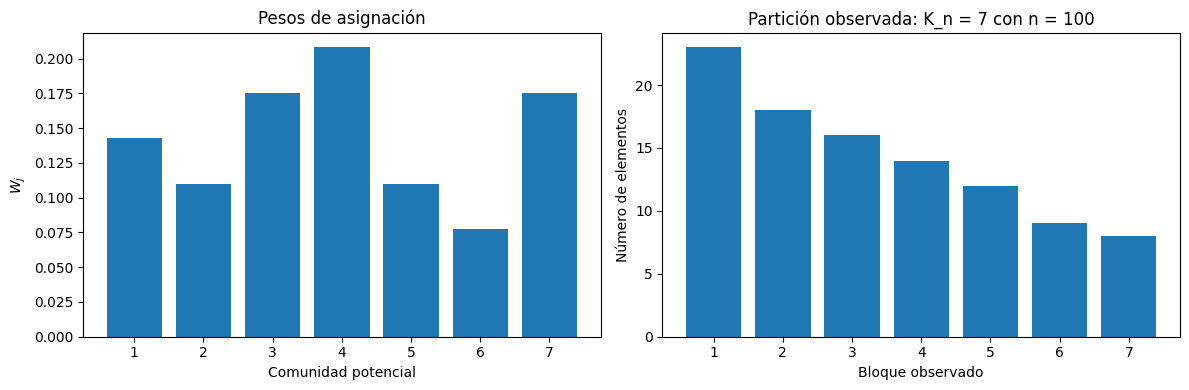

Número de comunidades potenciales: 7
Victorias por comunidad: [3 2 4 5 2 1 4]
Pesos: [0.143 0.11  0.176 0.208 0.11  0.078 0.176]
Tamaños de los bloques: [14, 12, 18, 23, 16, 8, 9]


In [8]:

import matplotlib.pyplot as plt

res = sample_pcpp(
    n=100,
    theta=4,
    omega=0.8,
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pesos de las comunidades potenciales
axes[0].bar(
    np.arange(res["M"]) + 1,
    res["W"]
)
axes[0].set(
    title="Pesos de asignación",
    xlabel="Comunidad potencial",
    ylabel=r"$W_j$"
)

# Tamaños de los bloques observados
axes[1].bar(
    np.arange(1, res["K_n"] + 1),
    sorted(res["block_sizes"], reverse=True)
)
axes[1].set(
    title=f"Partición observada: K_n = {res['K_n']} con n = 100",
    xlabel="Bloque observado",
    ylabel="Número de elementos"
)

plt.tight_layout()
plt.show()

print("Número de comunidades potenciales:", res["M"])
print("Victorias por comunidad:", res["D"])
print("Pesos:", np.round(res["W"], 3))
print("Tamaños de los bloques:", res["block_sizes"])

# Efecto de $\omega$

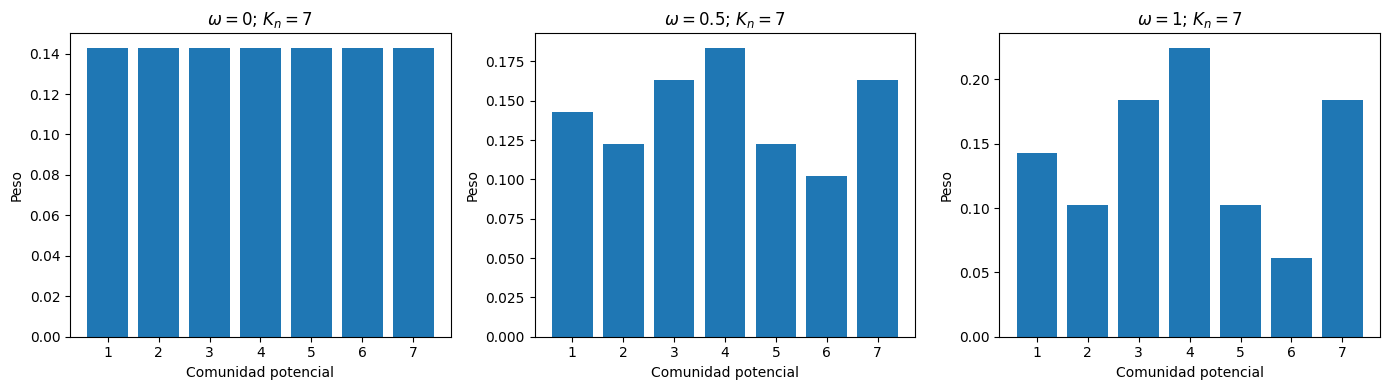

In [7]:

thetas = [4]
omegas = [0, 0.5, 1]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, omega in zip(axes, omegas):
    res = sample_pcpp(
        n=100,
        theta=4,
        omega=omega,
        random_state=42
    )

    ax.bar(np.arange(1, res["M"] + 1), res["W"])
    ax.set_title(
        rf"$\omega={omega}$; $K_n={res['K_n']}$"
    )
    ax.set_xlabel("Comunidad potencial")
    ax.set_ylabel("Peso")

plt.tight_layout()
plt.show()

# Efecto de $\theta$

In [6]:

import pandas as pd

def monte_carlo_pcpp(n, theta, omega, B=1000, seed=123):
    rng = np.random.default_rng(seed)
    K_values = []

    for _ in range(B):
        res = sample_pcpp(
            n=n,
            theta=theta,
            omega=omega,
            random_state=int(rng.integers(0, 2**32))
        )
        K_values.append(res["K_n"])

    return np.array(K_values)


thetas = [0.5, 1, 2, 4, 8, 12]
n = 100
omega = 0.7
B = 1000

results = []

for theta in thetas:
    K = monte_carlo_pcpp(
        n=n,
        theta=theta,
        omega=omega,
        B=B,
        seed=123
    )

    results.append({
        "theta": theta,
        "E_K_n_estimada": K.mean(),
        "Desviacion_estandar": K.std(ddof=1),
        "Mediana": np.median(K),
        "Minimo": K.min(),
        "Maximo": K.max()
    })

df = pd.DataFrame(results)
print(df.round(3))

   theta  E_K_n_estimada  Desviacion_estandar  Mediana  Minimo  Maximo
0    0.5           1.501                0.726      1.0       1       5
1    1.0           2.010                1.045      2.0       1       8
2    2.0           3.029                1.449      3.0       1       8
3    4.0           5.029                2.045      5.0       1      14
4    8.0           9.045                2.854      9.0       1      18
5   12.0          13.015                3.538     13.0       2      27
